In [1]:
import sys
import os
import pickle
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib import pyplot as plt, colors as mplcolors, patches, ticker, cm

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
sys.path.append(os.path.join(os.getcwd(), '../../../worm-2025-fieseler/src/'))
from utils_fly import read_utils as read_utils_fly
from utils_worm import read_utils as read_utils_worm

sys.path.append(os.path.join(os.getcwd(), '../../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils_fly)
importlib.reload(read_utils_worm)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id_fly = 0
file_id_worm = 24

In [4]:
path_worm = os.path.join(read_utils_worm.get_data_path(), 'exported_data_gcamp')
path_fly = os.path.join(read_utils_fly.get_data_path(), 'brain')

# read
(filename_worm,
 traces_worm,
 continuous_behaviors_worm,
 discrete_states_worm, eigenworms_worm,
 kymograph_worm) = read_utils_worm.get_data(path_worm, file_id_worm)
timestamps_worm = read_utils_worm.get_timestamps(read_utils_worm.get_file_handle(path_worm, file_id_worm))

(filename_fly,
 traces_fly,
 states_fly, markers_fly) = read_utils_fly.get_data(path_fly, file_id_fly)
timestamps_fly = read_utils_fly.get_timestamps(read_utils_fly.get_filepath(path_fly, file_id_fly))

# clear nan values
mask_worm = eigenworms_worm.notna().all(axis=1)

traces_worm = traces_worm[mask_worm]
continuous_behaviors_worm = continuous_behaviors_worm[mask_worm]
eigenworms_worm = eigenworms_worm[mask_worm]
discrete_states_worm = discrete_states_worm[mask_worm]
kymograph_worm = kymograph_worm[mask_worm]

mask_fly = markers_fly.notna().all(axis=1)

traces_fly = traces_fly[mask_fly]
markers_fly = markers_fly[mask_fly]
states_fly = states_fly[mask_fly]

# naive ID unknown neurons
traces_fly.columns = pd.Index([
	f'{file_id_fly:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces_fly.columns, traces_fly.columns == ''))
])
traces_worm.columns = pd.Index([
    f'{file_id_worm:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces_worm.columns, traces_worm.columns == ''))
])

# preprocess fly
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rate_fly = read_utils_fly.get_sampling_rate(os.path.join(path_fly, filename_fly))
traces_fly = pd.DataFrame(highpass_butter(traces_fly.values, sampling_rate_fly, 1 / 100), columns=traces_fly.columns)

/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/notebooks/exploration/../../src/utils_fly/read_utils.py:91: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  data = pickle.load(file)


In [9]:
(modes_manifold_worm,
 recos_manifold_worm,
 loads_pca_man_worm,
 vars_expl_mans_worm) = train_utils.get_manifolds_pca([traces_worm], scale=False,
												 n_pc=2)

traces_residual_worm = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip([traces_worm], recos_manifold_worm)][0]

In [10]:
(modes_manifold_fly,
 recos_manifold_fly,
 loads_pca_man_fly,
 vars_expl_mans_fly) = train_utils.get_manifolds_pca([traces_fly], scale=False,
												 n_pc=4)

traces_residuals_fly = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip([traces_fly], recos_manifold_fly)][0]

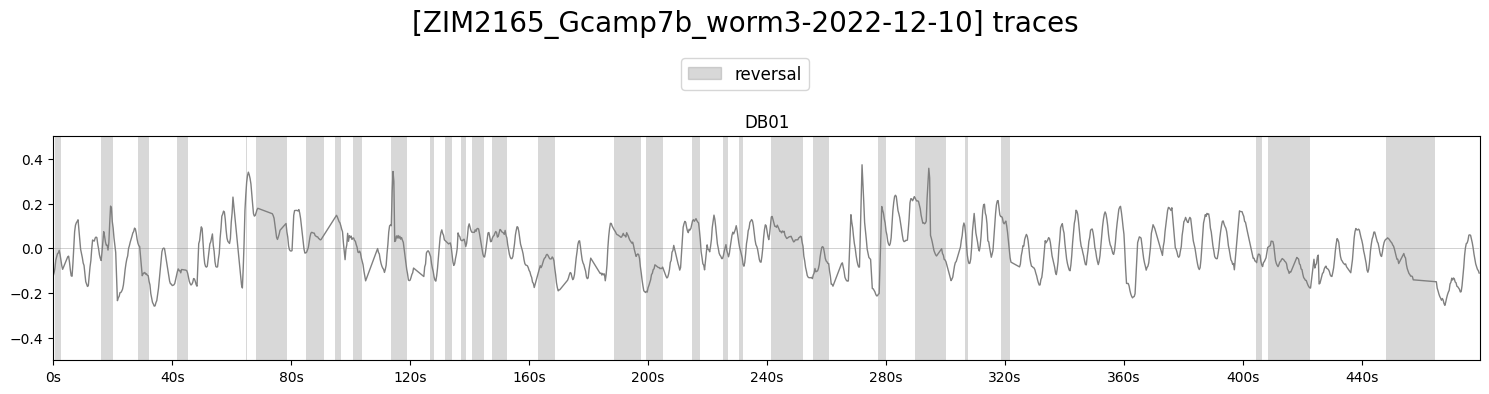

In [12]:
plot_utils.plot_traces(traces_worm.loc[:, ['DB01']],
					   discrete_states_worm[['REV']],
					   timestamps_worm,
					   label='reversal',
					   title=f'[{filename_worm}] traces',
					   n_plots=1, plots_per_row=1, top_space=1, ylimits=(-0.5, 0.5))

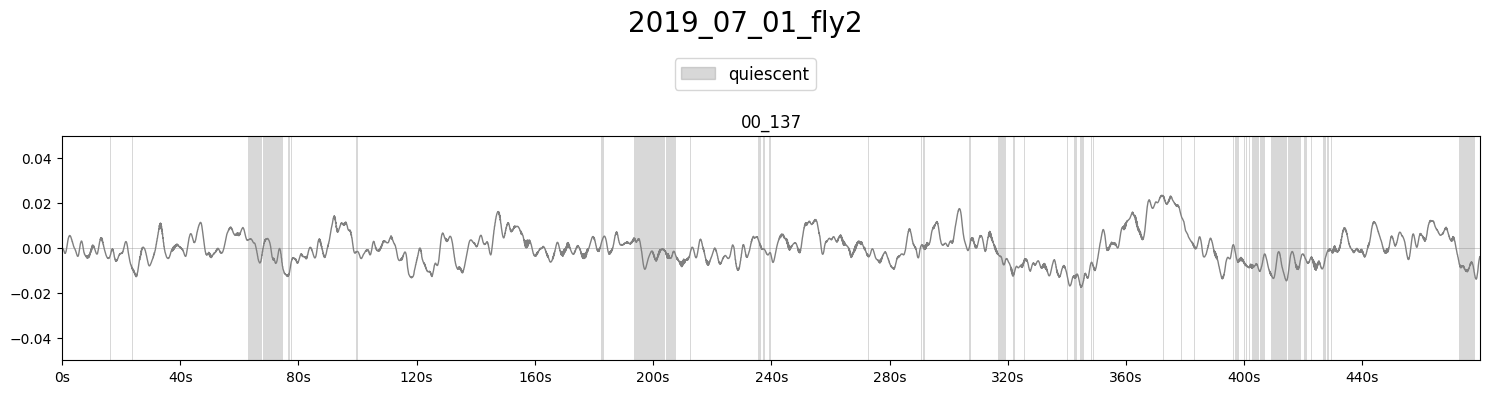

In [13]:
plot_utils.plot_traces(traces_fly.loc[:5300, ['00_137']],
					   states_fly.loc[:5300, 'still'],
					   timestamps_fly[:5300],
					   label='quiescent',
					   title=f'{filename_fly}',
					   n_plots=1, plots_per_row=1, top_space=1, ylimits=(-0.05, 0.05))